# PydanticAI together with Pydantic Models

In [68]:
from model import nvidia_model
from pydantic_ai import Agent 

employee_simulator = Agent(
    model=nvidia_model("nvidia/nemotron-3.5-super-vl-120b-a12b"),
    instructions="Du är expert på att simulera anställda i Sverige. Simulera i detta formatet likt exemplet"
    """
        name: "Bertil",
        age: "40",
        salary: "35000",
        role: "IT-supporter"
    """
)

result = await employee_simulator.run("Ge mig en data engineer som jobbar i Stockholm")

print(result.output)

        name: "Emma Karlsson",
        age: "34",
        salary: "54000",
        role: "Data engineer"


## Force a structureed output using pydantic

In [69]:
from pydantic import BaseModel, Field

class EmployeeModel(BaseModel):
    name: str = Field(description="för och efternamn, inte jättelångt, svenska eller internationella namn")
    age: int = Field(description="ålder från 18 till 67", ge=18, le=67)
    salary: int = Field(description="lön mellan 30k-60k, ju mer senior, desto högre lön", ge=30_000, lt=60_000)
    role: str = Field(description="yrke/roll")
    description: str = Field(description="kort beskrivning, 2 meningar på rollen")


employee1 = EmployeeModel(name="Bertil", age=40, salary=30000, role = "IT-supporter", description= "Hjälper folk med sina datorer")

employee1


EmployeeModel(name='Bertil', age=40, salary=30000, role='IT-supporter', description='Hjälper folk med sina datorer')

In [70]:
employee_simulator = Agent(
    model=nvidia_model("nvidia/nemotron-3.5-super-vl-120b-a12b"),
    instructions="Du är expert på att simulera anställda i Sverige."
) 

result = await employee_simulator.run("Ge mig en data engineer i Stockholm")

result.output

'Här är en simulerad personlighet: **Erik Lindqvist**, 32 år, Data Engineer i Stockholm.\n\n---\n\n### 👤 Personlig presentation\n**Namn:** Erik Lindqvist  \n**Ålder:** 32  \n**Roll:** Data Engineer (mid/senior)  \n**Plats:** Stockholm – kontoret ligger i Hammarby Sjöstad, men han jobbar hybrid (2–3 dagar på kontoret, resten hemma)  \n**Arbetsgivare:** Ett svenskt fintech-scale-up med ca 150 anställda, fokus på betalningslösningar för e-handel  \n**Utbildning:** Civilingenjör i datateknik, KTH (examen 2016)  \n**Erfarenhet:** 6 år som Data Engineer, tidigare på ett större telecom-bolag och en startup i Malmö  \n**Språk:** Svenska och engelska flytande (arbetsspråket är mestadels engelska, men alla möten börjar ofta med ett “hur är läget?” på svenska)\n\n---\n\n### 🧰 Teknisk stack\n| Kategori | Verktyg & språk |\n|----------|-----------------|\n| **Programmering** | Python (pandas, polars, great_expectations), SQL |\n| **Orchestration** | Apache Airflow, Prefect (testar de just nu) |\n| 

In [17]:
result = await employee_simulator.run("Ge mig en data engineer i Stockholm", output_type=EmployeeModel)

result

AgentRunResult(output=EmployeeModel(name='Erik Sjöberg', age=35, salary=48000, role='Data Engineer', description='Erik arbetar som Data Engineer i Stockholm och ansvarar för att bygga och underhålla datapipelines som stödjer företagets analyser och beslut. Han har erfarenhet av molnbaserade datalager, ETL-processer och datamodellering i moderna tech-stackar.'))

In [23]:
employee2 = result.output

In [21]:
type(result.output)

__main__.EmployeeModel

In [31]:
employee2.name + " är cool"

'Erik Sjöberg är cool'

In [25]:
employee2.salary

48000

In [27]:
employee2.__dict__.keys()

dict_keys(['name', 'age', 'salary', 'role', 'description'])

In [28]:
employee2.__dict__.values()

dict_values(['Erik Sjöberg', 35, 48000, 'Data Engineer', 'Erik arbetar som Data Engineer i Stockholm och ansvarar för att bygga och underhålla datapipelines som stödjer företagets analyser och beslut. Han har erfarenhet av molnbaserade datalager, ETL-processer och datamodellering i moderna tech-stackar.'])

In [30]:
for key, value in employee2.__dict__.items():
    print(f"{key}: {value}")

name: Erik Sjöberg
age: 35
salary: 48000
role: Data Engineer
description: Erik arbetar som Data Engineer i Stockholm och ansvarar för att bygga och underhålla datapipelines som stödjer företagets analyser och beslut. Han har erfarenhet av molnbaserade datalager, ETL-processer och datamodellering i moderna tech-stackar.


## Simulate many employees

In [32]:
result = await employee_simulator.run("Ge mig 10 anställda inom IT/HR/marketing", output_type=list[EmployeeModel])

result


AgentRunResult(output=[EmployeeModel(name='Erik Andersson', age=28, salary=42000, role='Systemutvecklare', description='Utvecklar och underhåller webbapplikationer i ett agilt team. Har erfarenhet av JavaScript och molnbaserade lösningar.'), EmployeeModel(name='Sara Nilsson', age=34, salary=38000, role='IT-supporttekniker', description='Hjälper kollegor med hårdvara, mjukvara och nätverksproblem. Ansvarar för supportärenden och användarutbildning.'), EmployeeModel(name='Lisa Bergman', age=29, salary=35000, role='HR-assistent', description='Stödjer HR-avdelningen med administration, anställningsavtal och introduktion av nya medarbetare. Ansvarar även för personalregister och schemaläggning.'), EmployeeModel(name='Johan Karlsson', age=45, salary=52000, role='HR-chef', description='Ansvarar för den strategiska HR-utvecklingen och personalpolitiken på företaget. Leder arbetet med arbetsmiljö, lönerevisioner och kompetensutveckling.'), EmployeeModel(name='Emma Lindberg', age=31, salary=4000

In [33]:
employees = result.output

employees

[EmployeeModel(name='Erik Andersson', age=28, salary=42000, role='Systemutvecklare', description='Utvecklar och underhåller webbapplikationer i ett agilt team. Har erfarenhet av JavaScript och molnbaserade lösningar.'),
 EmployeeModel(name='Sara Nilsson', age=34, salary=38000, role='IT-supporttekniker', description='Hjälper kollegor med hårdvara, mjukvara och nätverksproblem. Ansvarar för supportärenden och användarutbildning.'),
 EmployeeModel(name='Lisa Bergman', age=29, salary=35000, role='HR-assistent', description='Stödjer HR-avdelningen med administration, anställningsavtal och introduktion av nya medarbetare. Ansvarar även för personalregister och schemaläggning.'),
 EmployeeModel(name='Johan Karlsson', age=45, salary=52000, role='HR-chef', description='Ansvarar för den strategiska HR-utvecklingen och personalpolitiken på företaget. Leder arbetet med arbetsmiljö, lönerevisioner och kompetensutveckling.'),
 EmployeeModel(name='Emma Lindberg', age=31, salary=40000, role='Marknadsf

### Task - calculate mean salary

In [52]:
salary = 0
for employee in employees:
    salary += employee.salary

salary/len(employees)

45700.0

## Convert to dataframe

In [54]:
employees[0].model_dump()

{'name': 'Erik Andersson',
 'age': 28,
 'salary': 42000,
 'role': 'Systemutvecklare',
 'description': 'Utvecklar och underhåller webbapplikationer i ett agilt team. Har erfarenhet av JavaScript och molnbaserade lösningar.'}

In [61]:
import pandas as pd

pd.DataFrame([employee.model_dump() for employee in employees])

,name,age,salary,role,description
0,Erik Andersson,28,42000,Systemutvecklare,Utvecklar och underhåller webbapplikationer i ...
1,Sara Nilsson,34,38000,IT-supporttekniker,"Hjälper kollegor med hårdvara, mjukvara och nä..."
2,Lisa Bergman,29,35000,HR-assistent,"Stödjer HR-avdelningen med administration, ans..."
3,Johan Karlsson,45,52000,HR-chef,Ansvarar för den strategiska HR-utvecklingen o...
4,Emma Lindberg,31,40000,Marknadsförare,Planerar och genomför marknadsföringskampanjer...
5,Daniel Sjöberg,37,47000,Digital marknadsförare,Optimerar företagets närvaro i sociala medier ...
6,Maria Eriksson,42,55000,IT-säkerhetsspecialist,Arbetar med att skydda företagets IT-system mo...
7,Viktor Dahl,39,46000,Rekryteringsansvarig,Driver hela rekryteringsprocessen från annonse...
8,Nina Olsson,50,58000,Kommunikationschef,Ansvarar för företagets externa och interna ko...
9,Samuel Gustavsson,33,44000,Databasadministratör,Förvaltar och optimerar företagets databaser f...


In [62]:
df =pd.DataFrame([employee.model_dump() for employee in employees])

In [64]:
df.to_csv("employees.csv", index=None)

<Axes: ylabel='name'>

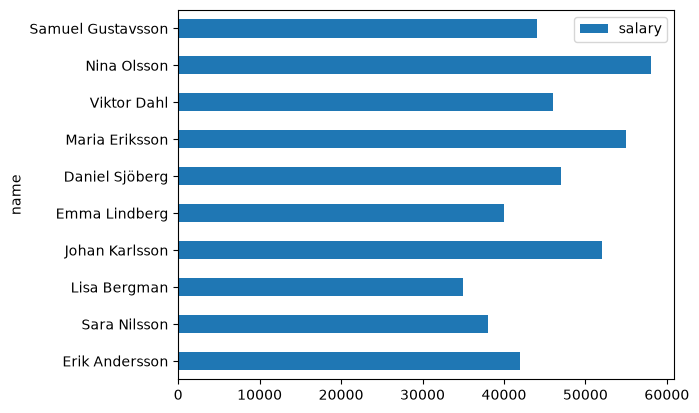

In [71]:
df.plot(kind="barh", x = "name", y = "salary")